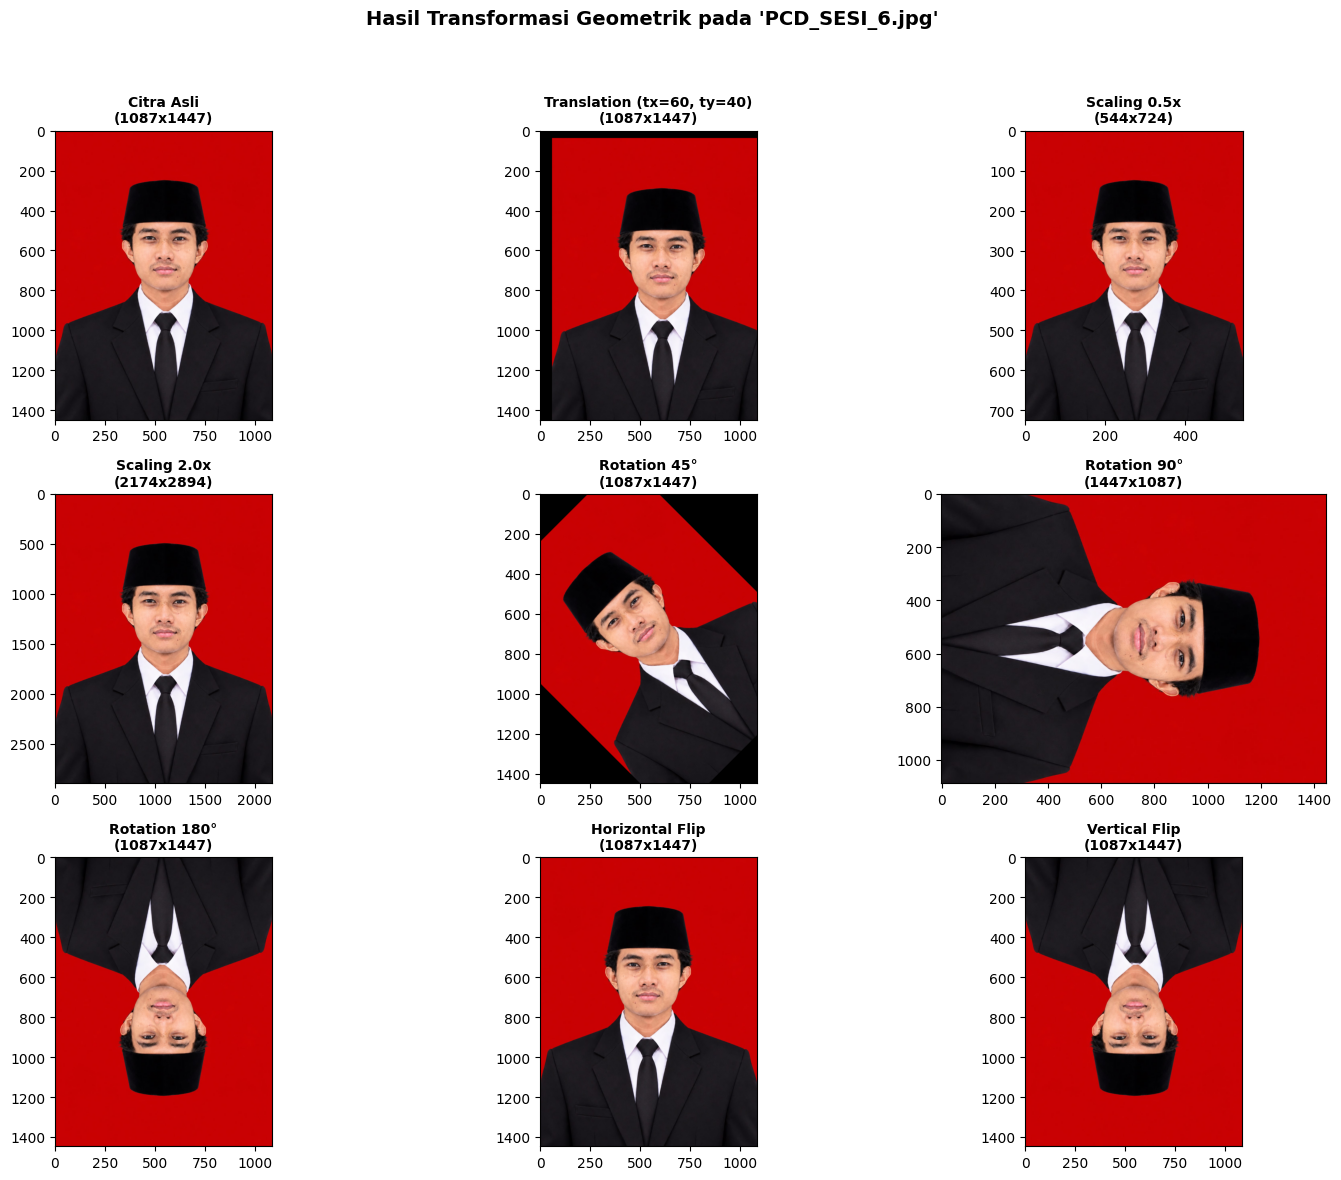

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

nama_file = "PCD_SESI_6.jpg"
img_bgr = cv2.imread(nama_file)

if img_bgr is None:
    raise FileNotFoundError(f"File '{nama_file}' tidak ditemukan di folder kerja.")

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
h, w = img_rgb.shape[:2]

tx, ty = 60, 40
M_trans = np.float32([
    [1, 0, tx],
    [0, 1, ty]
])
img_translation = cv2.warpAffine(img_rgb, M_trans, (w, h))

img_scale_05 = cv2.resize(img_rgb, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
img_scale_20 = cv2.resize(img_rgb, None, fx=2.0, fy=2.0, interpolation=cv2.INTER_CUBIC)

pusat = (w // 2, h // 2)
M_rot45 = cv2.getRotationMatrix2D(pusat, 45, 1.0)
img_rot_45 = cv2.warpAffine(img_rgb, M_rot45, (w, h))

img_rot_90 = cv2.rotate(img_rgb, cv2.ROTATE_90_CLOCKWISE)
img_rot_180 = cv2.rotate(img_rgb, cv2.ROTATE_180)

img_flip_h = cv2.flip(img_rgb, 1)
img_flip_v = cv2.flip(img_rgb, 0)

daftar_citra = [
    (f"Citra Asli\n({w}x{h})", img_rgb),
    (f"Translation (tx={tx}, ty={ty})\n({img_translation.shape[1]}x{img_translation.shape[0]})", img_translation),
    (f"Scaling 0.5x\n({img_scale_05.shape[1]}x{img_scale_05.shape[0]})", img_scale_05),
    (f"Scaling 2.0x\n({img_scale_20.shape[1]}x{img_scale_20.shape[0]})", img_scale_20),
    (f"Rotation 45°\n({img_rot_45.shape[1]}x{img_rot_45.shape[0]})", img_rot_45),
    (f"Rotation 90°\n({img_rot_90.shape[1]}x{img_rot_90.shape[0]})", img_rot_90),
    (f"Rotation 180°\n({img_rot_180.shape[1]}x{img_rot_180.shape[0]})", img_rot_180),
    (f"Horizontal Flip\n({img_flip_h.shape[1]}x{img_flip_h.shape[0]})", img_flip_h),
    (f"Vertical Flip\n({img_flip_v.shape[1]}x{img_flip_v.shape[0]})", img_flip_v),
]

plt.figure(figsize=(15, 12))
plt.suptitle(f"Hasil Transformasi Geometrik pada '{nama_file}'", fontsize=14, fontweight='bold')

for idx, (judul, citra) in enumerate(daftar_citra, start=1):
    plt.subplot(3, 3, idx)
    plt.imshow(citra)
    plt.title(judul, fontsize=10, fontweight='bold')
    plt.axis("on")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("hasil_transformasi_geometrik.png", dpi=300)
plt.show()